# L7 — Figures de la soutenance

Les trois figures qui manquaient pour présenter : le classement final avec intervalles de confiance,
la dégradation par sévérité (H2/H4), et la correction à charge égale (H3). Les autres figures de la
soutenance existent déjà : `L1_05` (coude du délai), `L2_01` (fuite), `L3_03` (ablation LightGBM),
`L5_01` (le graphe), `L5_02` (courbes d'apprentissage), `L6_01` (erreur vs ρ).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS_DIR
from src.contracts import load_events
from src.evaluate import evaluation_frame
from src.metrics import regression_metrics
from src.plotting import NEUTRAL, savefig, set_style

set_style()
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b7c0c9"
NAMES = {"gnn_gatv2": "GNN (GATv2)", "lgbm": "LightGBM", "mlp_flat": "MLP plat", "ridge": "Ridge",
         "analytic_mm1": "M/M/1", "gnn_k0": "GNN K=0", "naive_median_slice": "Baseline naïve"}

## S_01 — Le classement final, avec intervalles de confiance

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


figure -> C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\reports\figures\L7_01_classement_final.png


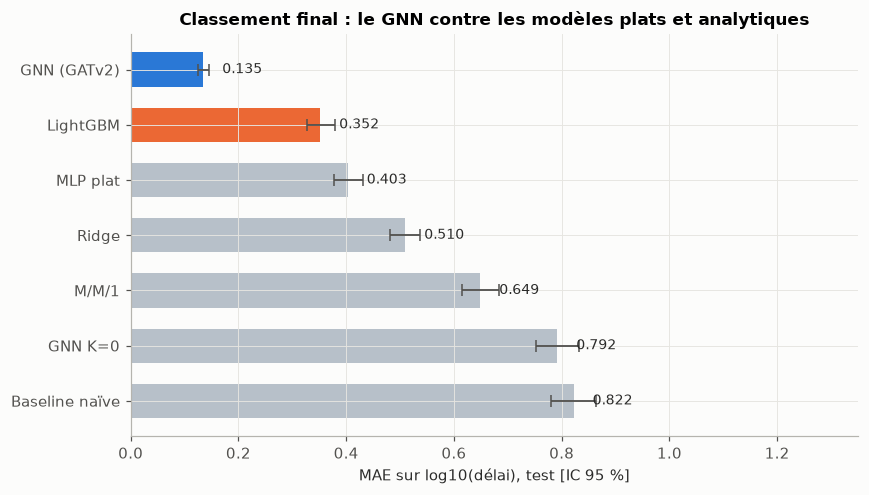

In [2]:
ci = pd.read_csv(RESULTS_DIR / "bootstrap_ci.csv")
d = ci[(ci.split == "test") & (ci.subset == "all") & (ci.slice_type == "ALL") & (ci.metric == "mae")
       & (ci.model.isin(NAMES))].sort_values("value")
colors = [BLUE if m == "gnn_gatv2" else ORANGE if m == "lgbm" else GREY for m in d.model]

fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(d))
ax.barh(y, d.value, color=colors, height=0.62,
        xerr=[d.value - d.ci_lo, d.ci_hi - d.value], error_kw=dict(ecolor=NEUTRAL, lw=1.2, capsize=4))
for i, v in enumerate(d.value):
    ax.text(v + 0.035, i, f"{v:.3f}", va="center", fontsize=9, color="#2b2b2a")
ax.set(yticks=y, yticklabels=[NAMES[m] for m in d.model], xlabel="MAE sur log10(délai), test [IC 95 %]",
       title="Classement final : le GNN contre les modèles plats et analytiques", xlim=(0, 1.35))
ax.invert_yaxis()
fig.tight_layout()
print("figure ->", savefig(fig, "L7_01_classement_final"))

## S_02 — La dégradation croît avec la sévérité (H2 + H4)

figure -> C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\reports\figures\L7_02_severite.png


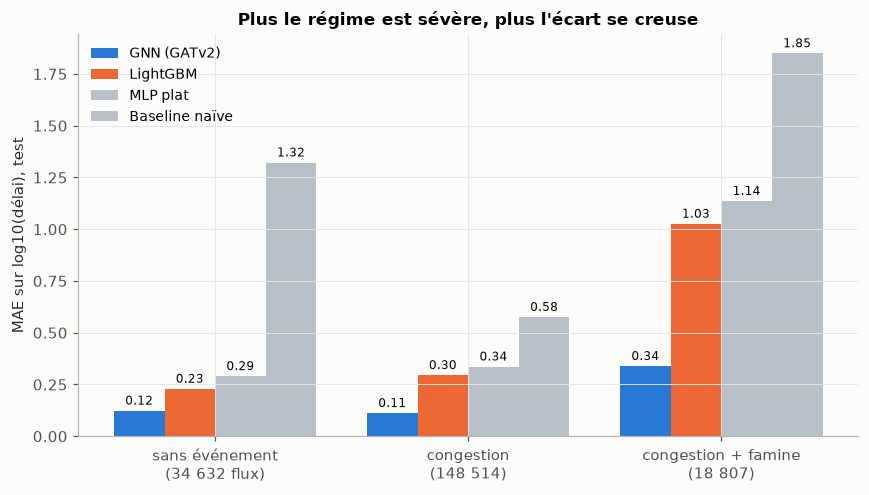

In [3]:
ev = load_events()[["scenario_id", "flow_id", "is_event_tau_2", "event_type"]]
f = evaluation_frame().merge(ev, on=["scenario_id", "flow_id"], how="left")
f = f[f.split == "test"]
MAIN = ["gnn_gatv2", "lgbm", "mlp_flat", "naive_median_slice"]
rows = [{"model": m, "seed": s, "cat": c, "mae": regression_metrics(g.y, g.pred)["mae_log"]}
        for (m, s, c), g in f[f.model.isin(MAIN)].groupby(["model", "seed", "event_type"], observed=True)]
cat = pd.DataFrame(rows).groupby(["model", "cat"]).mae.mean().unstack()[["none", "congestion", "both"]]

fig, ax = plt.subplots(figsize=(8, 4.6))
x, w = np.arange(3), 0.2
for i, m in enumerate(MAIN):
    c = BLUE if m == "gnn_gatv2" else ORANGE if m == "lgbm" else GREY
    bars = ax.bar(x + (i - 1.5) * w, cat.loc[m], width=w, color=c, label=NAMES[m])
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set(xticks=x, xticklabels=["sans événement\n(34 632 flux)", "congestion\n(148 514)", "congestion + famine\n(18 807)"],
       ylabel="MAE sur log10(délai), test", title="Plus le régime est sévère, plus l'écart se creuse")
ax.legend(fontsize=9)
fig.tight_layout()
print("figure ->", savefig(fig, "L7_02_severite"))

## S_03 — H3 : l'écart disparaît une fois la charge égalisée

figure -> C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\reports\figures\L7_03_charge_egale.png


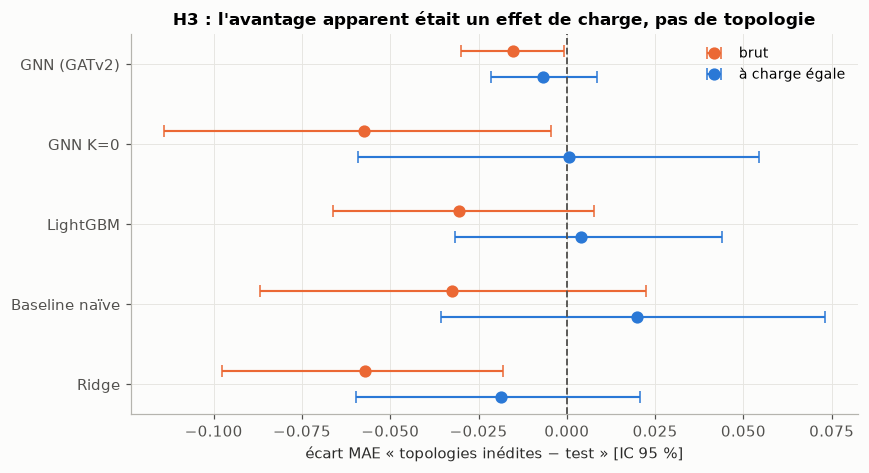

In [4]:
lm = pd.read_csv(RESULTS_DIR / "bootstrap_load_matched.csv")
lm = lm[lm.model.isin(["gnn_gatv2", "gnn_k0", "lgbm", "ridge", "naive_median_slice"])]

fig, ax = plt.subplots(figsize=(8, 4.4))
models = lm.model.unique()
for i, m in enumerate(models):
    for j, (lab, col, off) in enumerate([("brut", ORANGE, -0.16), ("à charge égale", BLUE, 0.16)]):
        r = lm[(lm.model == m) & (lm.comparaison == ("brut" if j == 0 else "charge_egale"))].iloc[0]
        ax.errorbar(r.diff_unseen_moins_test, i + off, xerr=[[r.diff_unseen_moins_test - r.ci_lo],
                    [r.ci_hi - r.diff_unseen_moins_test]], fmt="o", ms=7, color=col, capsize=4, lw=1.4,
                    label=lab if i == 0 else None)
ax.axvline(0, color=NEUTRAL, lw=1.2, ls="--")
ax.set(yticks=np.arange(len(models)), yticklabels=[NAMES[m] for m in models],
       xlabel="écart MAE « topologies inédites − test » [IC 95 %]",
       title="H3 : l'avantage apparent était un effet de charge, pas de topologie")
ax.invert_yaxis()
ax.legend(fontsize=9)
fig.tight_layout()
print("figure ->", savefig(fig, "L7_03_charge_egale"))

Un point à gauche de la ligne pointillée = meilleur sur les topologies inédites. En brut (orange) tous les
modèles semblent mieux généraliser ; à charge égale (bleu) les intervalles recouvrent 0 — l'écart venait de ce
que les topologies retenues sont moins chargées (ρ max médian 1,35 contre 1,63).